# T4 — Classificador k-Nearest Neighbour
**Alexsandro Narducci, Cláudio Strohaecker Junior e Lucas Cândido Belletti**

Implementação do 1-NN e do k-NN com distância euclidiana, com as quatro demonstrações (demoD1 a demoD4). Para executar, deixe os quatro arquivos `.mat` na mesma pasta do notebook e rode as células em ordem.

In [1]:
# Integrantes: Alexsandro Narducci, Cláudio Strohaecker Junior, Lucas Cândido Belletti
import numpy as np
from scipy.io import loadmat
import matplotlib.pyplot as plt
from pathlib import Path

# Procura os arquivos .mat na pasta atual ou em src.
arquivos_dados = [f'grupoDados{i}.mat' for i in range(1, 5)]
PASTA_DADOS = next((p.resolve() for p in (Path('.'), Path('src'))
                    if all((p / nome).is_file() for nome in arquivos_dados)), None)
if PASTA_DADOS is None:
    raise FileNotFoundError(f'Os quatro arquivos grupoDados1.mat a grupoDados4.mat devem estar na pasta atual ou em src. Pasta atual: {Path.cwd()}')
print(f'Pasta dos dados: {PASTA_DADOS}')
plt.rcParams.update({'figure.figsize': (7, 4), 'axes.grid': True,
                     'grid.alpha': 0.2, 'font.size': 10})


def dist(p, q):
    # Distância euclidiana entre dois vetores de atributos.
    return np.sqrt(np.sum((np.asarray(p, dtype=float) - np.asarray(q, dtype=float)) ** 2))


def meuKnn(dadosTrain, rotuloTrain, dadosTeste, k):
    rotuloTrain = np.asarray(rotuloTrain).reshape(-1)
    previstos = []
    # Para cada exemplo de teste
    for exemplo in dadosTeste:
        # Calcula a distância entre o exemplo de teste e os dados de treino
        distancias = [dist(exemplo, linha) for linha in dadosTrain]
        # Ordena as distâncias; ind guarda a posição de cada elemento ordenado
        ind = np.argsort(distancias, kind='stable')
        # Rótulos dos k exemplos mais próximos
        vizinhos = rotuloTrain[ind[:k]]
        # Moda dos rótulos = rótulo previsto (se empatar, fica o menor rótulo)
        valores, contagens = np.unique(vizinhos, return_counts=True)
        previstos.append(valores[np.argmax(contagens)])
    return np.array(previstos)


def normalizacao(dadosTrain, dadosTeste):
    # Normalização min-max por coluna. Mínimo e máximo vêm só do treino
    # e a mesma transformação é aplicada ao teste.
    treino = np.asarray(dadosTrain, dtype=float)
    teste = np.asarray(dadosTeste, dtype=float)
    minimo = treino.min(axis=0)
    amplitude = treino.max(axis=0) - minimo
    amplitude[amplitude == 0] = 1  # evita divisão por zero em coluna constante
    return (treino - minimo) / amplitude, (teste - minimo) / amplitude


def visualizaPontos(dados, rotulos, d1, d2, titulo='Distribuição dos exemplos'):
    # Mostra as dimensões d1 e d2 (contadas a partir de 1) de cada classe.
    dados = np.asarray(dados)
    rotulos = np.asarray(rotulos).reshape(-1)
    fig, ax = plt.subplots()
    cores = ['red', 'blue', 'green']
    marcadores = ['^', '+', '.']
    for i, rotulo in enumerate(sorted(set(rotulos))):
        x = [linha[d1 - 1] for linha, r in zip(dados, rotulos) if r == rotulo]
        y = [linha[d2 - 1] for linha, r in zip(dados, rotulos) if r == rotulo]
        ax.scatter(x, y, c=cores[i % 3], marker=marcadores[i % 3],
                   label=f'Classe {rotulo}', alpha=0.8)
    ax.set(xlabel=f'Atributo {d1}', ylabel=f'Atributo {d2}', title=titulo)
    ax.legend()
    fig.tight_layout()
    plt.show()

Pasta dos dados: /home/claude/novo


## demoD1 — Flores (Iris)
Conferência dos valores de referência e comparação de atributos. Os índices de colunas no código começam em zero; os números apresentados nas saídas começam em um.

Treino: (100, 4); teste: (50, 4)
k=1: 96.00% | k=10: 94.00%
Maior acurácia: 98.00% (k=3)
Características 3 e 4 | k=4: 49/50 = 98.00%


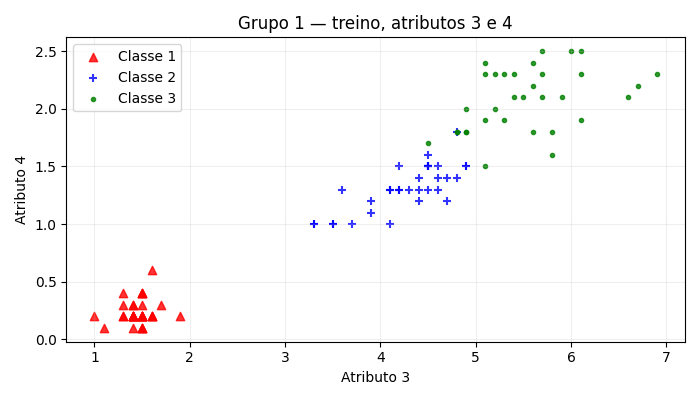

In [2]:
# Integrantes: Alexsandro Narducci, Cláudio Strohaecker Junior, Lucas Cândido Belletti
# Q1.1: A maior acurácia que conseguimos foi 98% (49/50), com as 4 características
#       e k=3. Com k=1 dá 96% e com k=10 dá 94%, como no enunciado.
# Q1.2: Não. Usando só as características 3 e 4 (k=4) também chega a 98%,
#       então nem todas as características são necessárias.
mat1 = loadmat(PASTA_DADOS / 'grupoDados1.mat')
x1, y1 = mat1['grupoTrain'], mat1['trainRots'].reshape(-1)
t1, r1 = mat1['grupoTest'], mat1['testRots'].reshape(-1)
print(f'Treino: {x1.shape}; teste: {t1.shape}')

# Acurácia para k de 1 a 20 com as 4 características
acuracias1 = []
for k in range(1, 21):
    previsto = meuKnn(x1, y1, t1, k)
    acuracias1.append(sum(int(p == r) for p, r in zip(previsto, r1)) / len(r1))
print(f'k=1: {acuracias1[0]:.2%} | k=10: {acuracias1[9]:.2%}')
print(f'Maior acurácia: {max(acuracias1):.2%} (k={acuracias1.index(max(acuracias1)) + 1})')

# Só as características 3 e 4 (índices 2 e 3)
previsto = meuKnn(x1[:, [2, 3]], y1, t1[:, [2, 3]], 4)
corretos = sum(int(p == r) for p, r in zip(previsto, r1))
print(f'Características 3 e 4 | k=4: {corretos}/{len(r1)} = {corretos/len(r1):.2%}')
visualizaPontos(x1, y1, 3, 4, 'Grupo 1 — treino, atributos 3 e 4')

## demoD2 — Composição química dos vinhos
A normalização usa os mínimos e máximos do treino, sem consultar o teste para definir a transformação.

Amplitude dos atributos no treino:
Álcool                    :   11.030 a   14.830
Ácido málico              :    0.740 a    5.650
Cinzas                    :    1.360 a    3.230
Alcalinidade das cinzas   :   10.600 a   30.000
Magnésio                  :   70.000 a  162.000
Fenóis totais             :    0.980 a    3.880
Flavonóides               :    0.340 a    5.080
Fenóis não flavonóides    :    0.130 a    0.630
Proantocianinas           :    0.420 a    3.580
Intensidade de cor        :    1.280 a   13.000
Tonalidade                :    0.480 a    1.710
OD280/OD315               :    1.270 a    4.000
Prolina                   :  278.000 a 1547.000
Original | k=1: 41/60 = 68.33%
Min–max | k=1: 58/60 = 96.67%
Min–max | k=3: 59/60 = 98.33%


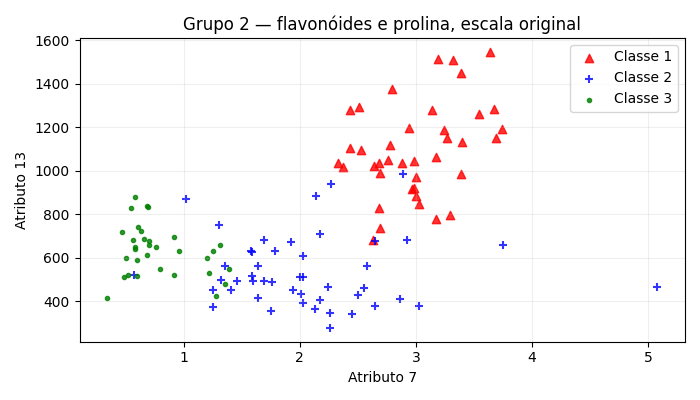

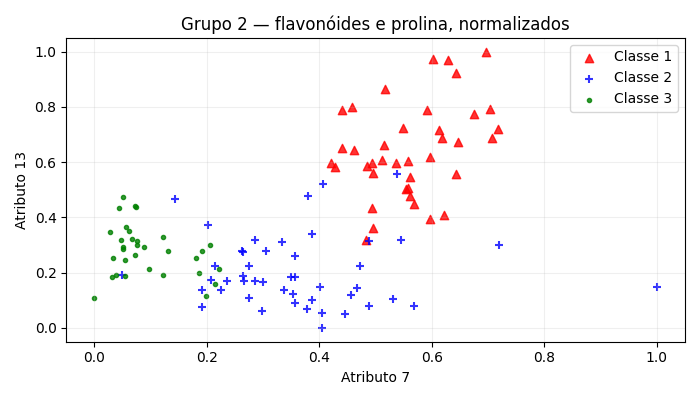

In [3]:
# Integrantes: Alexsandro Narducci, Cláudio Strohaecker Junior, Lucas Cândido Belletti
# Q2.1: Com os 13 atributos originais e k=1, a acurácia é 68,33% (41/60).
# Q2.2: Normalizando (min-max) e usando k=3 a acurácia sobe para 98,33% (59/60),
#       que é aproximadamente 98%.
# Por quê: os atributos têm escalas muito diferentes. A prolina vai de 278 a 1547
#       e a tonalidade de 0,48 a 1,71, então a prolina domina o cálculo da distância
#       e os outros atributos quase não pesam. A normalização deixa todos entre 0 e 1
#       (mínimo e máximo calculados no treino). O k=3 deixa a decisão por votação,
#       em vez de depender de um único vizinho.
mat2 = loadmat(PASTA_DADOS / 'grupoDados2.mat')
x2, y2 = mat2['grupoTrain'], mat2['trainRots'].reshape(-1)
t2, r2 = mat2['grupoTest'], mat2['testRots'].reshape(-1)
x2n, t2n = normalizacao(x2, t2)
nomes_atributos = ['Álcool', 'Ácido málico', 'Cinzas', 'Alcalinidade das cinzas',
                  'Magnésio', 'Fenóis totais', 'Flavonóides', 'Fenóis não flavonóides',
                  'Proantocianinas', 'Intensidade de cor', 'Tonalidade',
                  'OD280/OD315', 'Prolina']
print('Amplitude dos atributos no treino:')
for j, nome in enumerate(nomes_atributos):
    print(f'{nome:26s}: {min(x2[:, j]):8.3f} a {max(x2[:, j]):8.3f}')
for descricao, treino, teste, k in [
    ('Original', x2, t2, 1), ('Min–max', x2n, t2n, 1), ('Min–max', x2n, t2n, 3)]:
    previsto = meuKnn(treino, y2, teste, k)
    corretos = sum(int(p == r) for p, r in zip(previsto, r2))
    print(f'{descricao} | k={k}: {corretos}/{len(r2)} = {corretos/len(r2):.2%}')
visualizaPontos(x2, y2, 7, 13, 'Grupo 2 — flavonóides e prolina, escala original')
visualizaPontos(x2n, y2, 7, 13, 'Grupo 2 — flavonóides e prolina, normalizados')

## demoD3 — Sensibilidade a rótulos ruidosos
A comparação com o grupo 1 é usada apenas para diagnosticar a alteração dos dados. A classificação mantém os rótulos fornecidos no grupo 3.

Rótulos de treino diferentes do grupo 1: 33
k= 1: 35/50 = 70.00%
k= 7: 46/50 = 92.00%


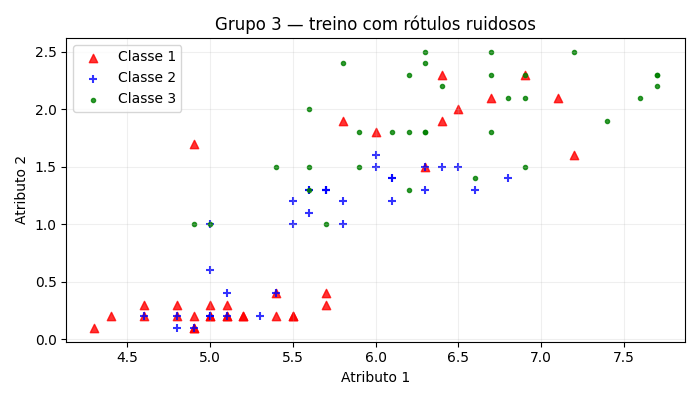

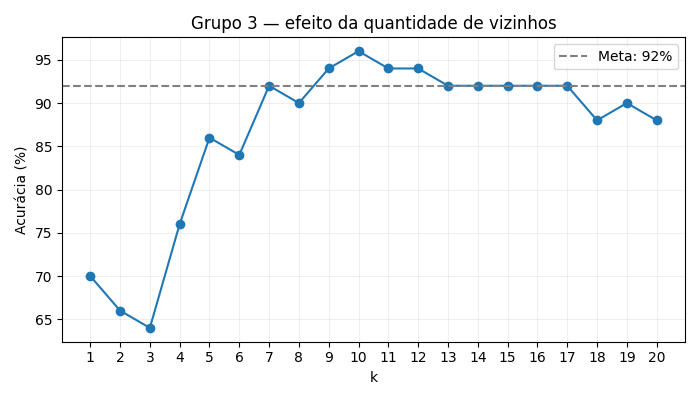

In [4]:
# Integrantes: Alexsandro Narducci, Cláudio Strohaecker Junior, Lucas Cândido Belletti
# Q3.1: Com k=1 a acurácia é 70% (35/50).
# Q3.2: Mantendo os dados e aumentando k para 7, a acurácia sobe para 92% (46/50).
# Por quê: os dados do grupo 3 são os mesmos do grupo 1 (atributos 1 e 4), mas 33
#       rótulos de treino estão diferentes, ou seja, o treino tem rótulos errados
#       (ruído). Com k=1 um único rótulo errado decide a classe do exemplo de teste.
#       Com k maior, os vizinhos corretos votam junto e o erro de um ou outro
#       rótulo é compensado. Não corrigimos nem removemos nenhum exemplo.
mat3 = loadmat(PASTA_DADOS / 'grupoDados3.mat')
x3, y3 = mat3['grupoTrain'], mat3['trainRots'].reshape(-1)
t3, r3 = mat3['grupoTest'], mat3['testRots'].reshape(-1)
print('Rótulos de treino diferentes do grupo 1:', sum(int(a != b) for a, b in zip(y3, y1)))
ks = list(range(1, 21))
acuracias3 = []
for k in ks:
    previsto = meuKnn(x3, y3, t3, k)
    corretos = sum(int(p == r) for p, r in zip(previsto, r3))
    acuracias3.append(corretos / len(r3))
    if k in (1, 7):
        print(f'k={k:2d}: {corretos}/{len(r3)} = {corretos/len(r3):.2%}')
visualizaPontos(x3, y3, 1, 2, 'Grupo 3 — treino com rótulos ruidosos')
fig, ax = plt.subplots()
ax.plot(ks, [100 * a for a in acuracias3], marker='o')
ax.axhline(92, color='gray', linestyle='--', label='Meta: 92%')
ax.set(xlabel='k', ylabel='Acurácia (%)', title='Grupo 3 — efeito da quantidade de vizinhos', xticks=ks)
ax.legend()
fig.tight_layout()
plt.show()

## demoD4 — Escalas e atributos pouco informativos
Comparamos o efeito de cada ajuste separadamente antes de combiná-los.

Quatro atributos originais     | k=1: 43/60 = 71.67%
Quatro atributos normalizados  | k=1: 47/60 = 78.33%
Atributos 1 e 2 originais      | k=1: 43/60 = 71.67%
Atributos 1 e 2 normalizados   | k=1: 56/60 = 93.33%
Atributos 1 e 2 normalizados   | k=3: 55/60 = 91.67%


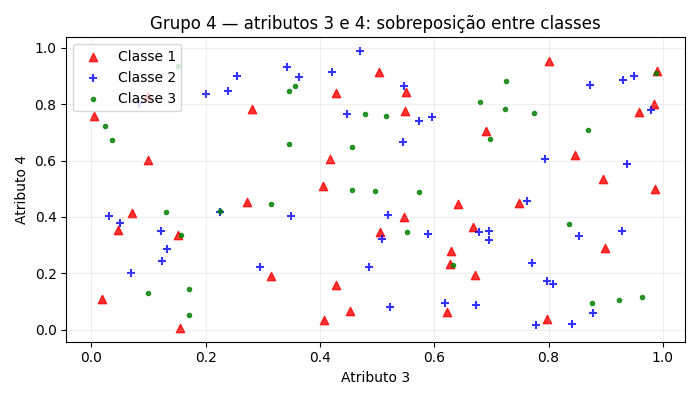

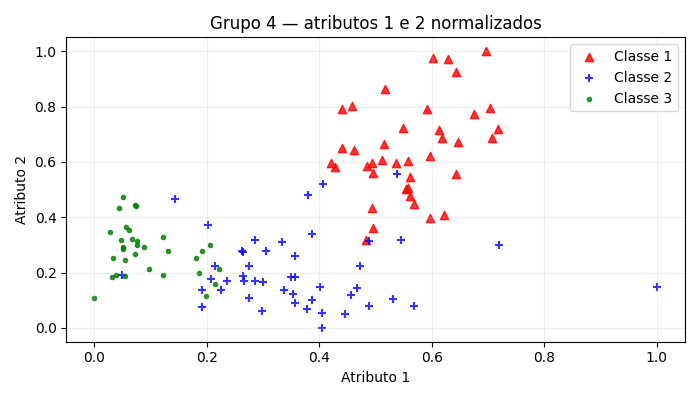

In [5]:
# Integrantes: Alexsandro Narducci, Cláudio Strohaecker Junior, Lucas Cândido Belletti
# Q4.1: Com os 4 atributos originais e k=1, a acurácia é 71,67% (43/60).
# Q4.2: Usando só os atributos 1 e 2, normalizados (min-max), com k=3 a acurácia
#       é 91,67% (55/60), aproximadamente 92%. Com k=1 chega a 93,33%.
# Por quê: há dois problemas.
#       1) Escalas diferentes: o atributo 2 tem amplitude muito maior e domina a
#          distância. Solução: normalizar.
#       2) Os atributos 3 e 4 não ajudam: no gráfico as classes ficam misturadas
#          nessas duas dimensões. Normalizar os 4 atributos dá só 78,33%, porque
#          esses dois atributos continuam atrapalhando. Solução: usar só 1 e 2.
mat4 = loadmat(PASTA_DADOS / 'grupoDados4.mat')
x4, y4 = mat4['trainSet'], mat4['trainLabs'].reshape(-1)
t4, r4 = mat4['testSet'], mat4['testLabs'].reshape(-1)
x4n, t4n = normalizacao(x4, t4)
x4s, t4s = x4[:, :2], t4[:, :2]
x4sn, t4sn = normalizacao(x4s, t4s)
for descricao, treino, teste, k in [
    ('Quatro atributos originais', x4, t4, 1),
    ('Quatro atributos normalizados', x4n, t4n, 1),
    ('Atributos 1 e 2 originais', x4s, t4s, 1),
    ('Atributos 1 e 2 normalizados', x4sn, t4sn, 1),
    ('Atributos 1 e 2 normalizados', x4sn, t4sn, 3)]:
    previsto = meuKnn(treino, y4, teste, k)
    corretos = sum(int(p == r) for p, r in zip(previsto, r4))
    print(f'{descricao:30s} | k={k}: {corretos}/{len(r4)} = {corretos/len(r4):.2%}')
visualizaPontos(x4, y4, 3, 4, 'Grupo 4 — atributos 3 e 4: sobreposição entre classes')
visualizaPontos(x4sn, y4, 1, 2, 'Grupo 4 — atributos 1 e 2 normalizados')